# 02 — Train ViT & ResNet and compare data efficiency

**Requires GPU** on Colab for reasonable ViT training time.

Install deps (Colab):
```bash
pip install -q -r ../requirements.txt
```

In [ ]:
%cd /content
!rm -rf /content/casting-defect-vit-resnet
!git clone https://github.com/anshikareddy403/casting-defect-vit-resnet.git

!pip install -q pillow pandas matplotlib scikit-learn pyyaml torch torchvision transformers

# Note: Please run this cell. It will ask you to upload 'casting_data.zip'.
from google.colab import files
files.upload()

!mkdir -p /content/casting-defect-vit-resnet/data/raw
!unzip -q -o /content/casting_data.zip -d /content/casting-defect-vit-resnet/data/raw

/content
Cloning into 'casting-defect-vit-resnet'...
remote: Enumerating objects: 39, done.
remote: Counting objects: 100% (39/39), done.
remote: Compressing objects: 100% (38/38), done.
remote: Total 39 (delta 2), reused 0 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (39/39), 56.81 KiB | 1.62 MiB/s, done.
Resolving deltas: 100% (2/2), done.


Saving casting_data.zip to casting_data.zip


In [ ]:
import os
import sys
from pathlib import Path

def _find_project_root() -> Path:
    for candidate in (
        Path('/content/casting-defect-vit-resnet'),
        Path.cwd(),
        Path('..').resolve(),
    ):
        if (candidate / 'src' / 'data.py').is_file():
            return candidate
    raise FileNotFoundError('Run git clone setup first.')

ROOT = _find_project_root()
os.chdir(ROOT)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import pandas as pd
import torch

from src.data import (
    load_all_samples,
    make_loaders,
    resolve_data_root,
    split_train_val,
    subset_train_stratified,
)
from src.evaluate import evaluate_model
from src.metrics import format_metrics_row
from src.train_resnet import train_resnet
from src.train_vit import train_vit
from src.utils import ensure_dir, load_config, resolve_device, set_seed
from src.visualize import plot_confusion_matrix, plot_training_history, save_gradcam_examples

cfg = load_config(ROOT / 'configs' / 'default.yaml')
set_seed(cfg['seed'])
device = resolve_device(cfg.get('device', 'auto'))
print('Device:', device)

Device: cuda


In [ ]:
data_root = resolve_data_root(cfg)
train_pool, test_samples, layout = load_all_samples(data_root, layout=cfg['data'].get('layout', 'auto'))

try:
    train_samples, val_samples = split_train_val(
        train_pool,
        val_fraction=cfg['data']['val_fraction'],
        seed=cfg['seed'],
        group_augmentations=cfg['data'].get('group_augmentations', True),
    )
except ValueError as e:
    print(f'Warning: Stratified split failed ({e}). Retrying with group_augmentations=False.')
    train_samples, val_samples = split_train_val(
        train_pool,
        val_fraction=cfg['data']['val_fraction'],
        seed=cfg['seed'],
        group_augmentations=False,
    )

FRACTION = 0.25  # change to 0.5 or 1.0 for other runs
MODEL = 'resnet'  # or 'vit'

try:
    train_subset = subset_train_stratified(
        train_samples,
        fraction=FRACTION,
        seed=cfg['seed'],
        group_augmentations=cfg['data'].get('group_augmentations', True),
    )
except ValueError as e:
    print(f'Warning: Stratified subset failed ({e}). Retrying with group_augmentations=False.')
    train_subset = subset_train_stratified(
        train_samples,
        fraction=FRACTION,
        seed=cfg['seed'],
        group_augmentations=False,
    )

train_loader, val_loader, test_loader = make_loaders(
    train_subset,
    val_samples,
    test_samples,
    image_size=cfg['data']['image_size'],
    batch_size=cfg['data']['batch_size'],
)
print(f'Model={MODEL} fraction={FRACTION} n_train={len(train_subset)}')

Model=resnet fraction=0.25 n_train=1409


In [ ]:
run_name = f"{MODEL}_frac{FRACTION}_seed{cfg['seed']}"
ckpt_path = ensure_dir(ROOT / cfg['paths']['checkpoints'] / run_name) / 'best.pt'

if MODEL == 'resnet':
    model, train_meta, history = train_resnet(train_loader, val_loader, device, cfg, ckpt_path)
    is_vit = False
else:
    model, train_meta, history = train_vit(train_loader, val_loader, device, cfg, ckpt_path)
    is_vit = True

eval_out = evaluate_model(model, test_loader, device, is_vit=is_vit)
row = format_metrics_row(
    model=MODEL,
    train_fraction=FRACTION,
    metrics=eval_out['metrics'],
    train_time_s=train_meta['train_time_s'],
    infer_latency_ms=eval_out['infer_latency_ms'],
    model_size_mb=eval_out['model_size_mb'],
    seed=cfg['seed'],
)
display(pd.DataFrame([row]))

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 169MB/s]
test: 100%|██████████| 23/23 [00:02<00:00,  9.89it/s]


,model,train_fraction,seed,accuracy,macro_f1,defect_precision,defect_recall,tn,fp,fn,tp,train_time_s,infer_latency_ms_mean,model_size_mb
0,resnet,0.25,42,0.995804,0.995485,0.997788,0.995585,261,1,2,451,152.178341,0.857256,42.675697


Saved figures to /content/casting-defect-vit-resnet/results/figures/resnet_frac0.25_seed42
ResNetGradCAM init parameters: ['self', 'model']


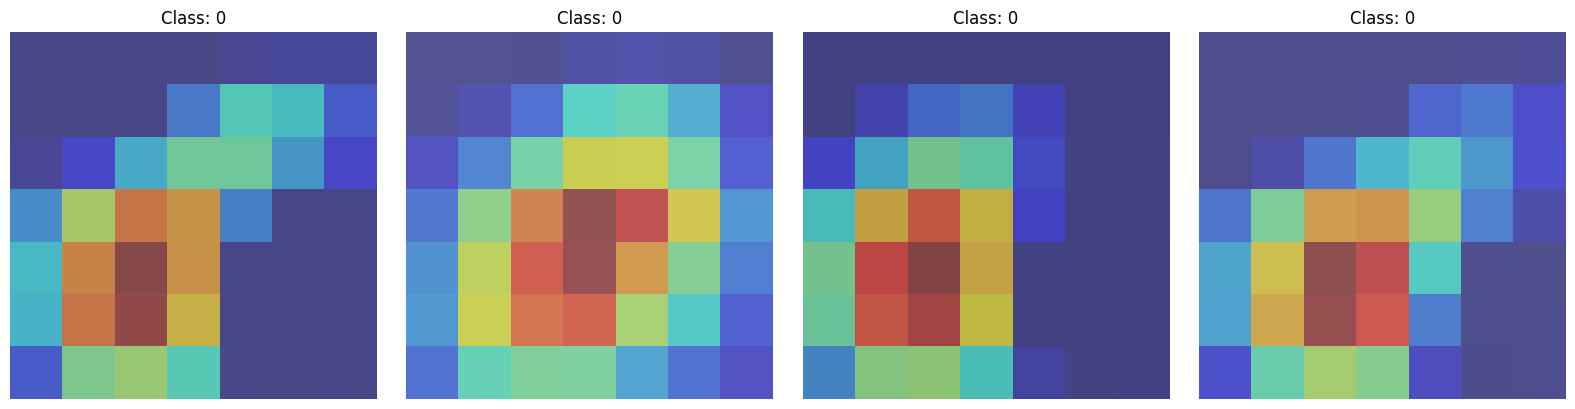

In [ ]:
fig_dir = ensure_dir(ROOT / cfg['paths']['figures'] / run_name)
plot_training_history(history, fig_dir / 'training_curves.png', title=run_name)
plot_confusion_matrix(eval_out['metrics']['confusion_matrix'], fig_dir / 'confusion_matrix.png', title=run_name)
print('Saved figures to', fig_dir)

if MODEL == 'resnet':
    import src.visualize as vis
    import inspect
    import matplotlib.pyplot as plt

    # Dynamically resolve class
    GradCamClass = getattr(vis, 'ResNetGradCAM')
    init_params = inspect.signature(GradCamClass.__init__).parameters
    print("ResNetGradCAM init parameters:", list(init_params.keys()))

    # Instantiate properly depending on arguments
    if 'target_layer' in init_params:
        cam = GradCamClass(model, target_layer=model.layer4[-1])
    else:
        cam = GradCamClass(model)

    images, labels = next(iter(test_loader))
    fig, axes = plt.subplots(1, 4, figsize=(16, 4))
    for i in range(min(4, len(images))):
        img_3d = images[i]  # Use 3D tensor to avoid the double unsqueeze 5D error
        heat = cam(img_3d.to(device), class_idx=int(labels[i].item()))

        mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
        std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)
        denorm = (img_3d * std + mean).permute(1, 2, 0).numpy().clip(0, 1)

        axes[i].imshow(denorm)
        axes[i].imshow(heat, cmap='jet', alpha=0.5)
        axes[i].set_title(f"Class: {labels[i].item()}")
        axes[i].axis('off')

    plt.tight_layout()
    plt.savefig(fig_dir / 'gradcam.png')
    plt.show()

## Full grid via CLI (recommended)

From repo root:
```bash
for m in resnet vit; do for f in 0.25 0.5 1.0; do python scripts/run_experiment.py --model $m --fraction $f; done; done
```
Then load `results/comparison_table.csv` for thesis tables.